# E2 — Sequence composition landscape

## Objective

Characterize sequence-composition patterns associated with phage lytic proteins and with the
clean functional subtypes defined in the frozen E0 universe.

This notebook starts **only from the frozen E0 table** and computes composition-oriented
descriptors with **Roxy**.

## Comparison contract

Inferential comparisons use the mutually exclusive `sequence_state` from E0. This prevents the
same exact sequence from appearing on both sides of a contrast even when its independent evidence
flags overlap.

### Global contrasts

1. `P_core` vs `N_easy`
2. `P_core` vs `N_hard`
3. `P_core` vs `N_mixed`, where `N_mixed = N_easy ∪ N_hard`
4. `N_easy` vs `N_hard` as a background-diagnostic contrast

### Clean subtype contrasts

Only curated `P_core` sequences with one clean subtype are used:

1. Endolysin vs Depolymerase
2. Endolysin vs VAL
3. Depolymerase vs VAL

`multiple_nonexclusive` and `other_phage_envelope_lytic_enzyme` remain available for descriptive
summaries but are excluded from clean pairwise subtype inference.

`U_explicit`, `U_other_unresolved`, and challenge groups are retained in descriptive composition
profiles but are not treated as confirmed positive or negative biological classes.

## Feature contract

Roxy exposes several outputs within each descriptor family. E2 deliberately separates them:

- **AAC inference** uses only the 20 normalized residue frequencies `aac_freq_<AA>`.
- **Complexity** excludes explicit length/count fields and the absolute longest-homopolymer run.
- **Compositional bias** excludes length and valid-residue counts.
- **Grouped composition** uses fractions and ratios, never raw group counts.

This prevents E2 from simply rediscovering the strong protein-length differences already described
in E1.

Ratio descriptors can be mathematically undefined when their denominator is zero. Those values are
retained as `NaN` and excluded only from the corresponding feature-level summary/test. No sequence
is removed globally because of an undefined ratio.

## Statistical reporting

For every feature and contrast the notebook reports:

- feature-specific usable sample sizes;
- missing counts;
- means and medians;
- mean and median differences;
- Mann–Whitney U;
- Cliff's delta;
- two-sided p-value;
- Benjamini–Hochberg FDR q-value.

For AAC frequencies, `log2_mean_ratio` is also reported as an enrichment/depletion measure.

Because the cohorts are large, biological interpretation should prioritize **effect direction,
effect magnitude, and consistency across contrasts**, not p-values alone.

## Outputs

- `EDA_results/E2/roxy_sequence_composition.parquet`
- `EDA_results/E2/roxy_feature_manifest.tsv`
- `EDA_results/E2/analysis_feature_manifest.tsv`
- `EDA_results/E2/composition_missingness.tsv`
- `EDA_results/E2/composition_group_summary.tsv`
- `EDA_results/E2/aac_effects_global.tsv`
- `EDA_results/E2/aac_effects_subtypes.tsv`
- `EDA_results/E2/composition_effects_global.tsv`
- `EDA_results/E2/composition_effects_subtypes.tsv`
- `EDA_results/E2/figures/*.png`
- `EDA_results/E2/figures/*.pdf`

In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from IPython.display import display

import roxy
from roxy import DESCRIPTOR_REGISTRY

sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.05,
)

pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 200)


def detect_roxy_version():
    module_version = getattr(roxy, "__version__", None)
    if module_version:
        return str(module_version)

    for distribution_name in ["roxy", "krenai-roxy"]:
        try:
            return version(distribution_name)
        except PackageNotFoundError:
            pass

    return "unknown"


ROXY_VERSION = detect_roxy_version()
print(f"Roxy version: {ROXY_VERSION}")

Roxy version: 0.2.0


## 1. Paths and frozen E0 input

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = PROJECT_ROOT / "EDA_results" / "E0" / "phagelytic_eda_universe.csv"

RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E2"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_PATH = RESULT_DIR / "roxy_sequence_composition.parquet"
FEATURE_MANIFEST_PATH = RESULT_DIR / "roxy_feature_manifest.tsv"
CACHE_METADATA_PATH = RESULT_DIR / "roxy_sequence_composition_metadata.json"

ANALYSIS_FEATURE_MANIFEST_PATH = RESULT_DIR / "analysis_feature_manifest.tsv"
MISSINGNESS_PATH = RESULT_DIR / "composition_missingness.tsv"
GROUP_SUMMARY_PATH = RESULT_DIR / "composition_group_summary.tsv"

AAC_GLOBAL_PATH = RESULT_DIR / "aac_effects_global.tsv"
AAC_SUBTYPE_PATH = RESULT_DIR / "aac_effects_subtypes.tsv"

COMPOSITION_GLOBAL_PATH = RESULT_DIR / "composition_effects_global.tsv"
COMPOSITION_SUBTYPE_PATH = RESULT_DIR / "composition_effects_subtypes.tsv"

if not E0_PATH.is_file():
    raise FileNotFoundError(f"Frozen E0 input not found: {E0_PATH}")

print(f"Project root : {PROJECT_ROOT}")
print(f"E0 input     : {E0_PATH}")
print(f"E2 results   : {RESULT_DIR}")

Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
E0 input     : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E0/phagelytic_eda_universe.csv
E2 results   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2


In [3]:
e0 = pd.read_csv(
    E0_PATH,
    dtype={
        "sequence_uid": str,
        "sequence": str,
        "sequence_state": str,
        "phage_lytic": str,
        "phage_lytic_subtype": str,
        "clean_subtype": str,
    },
    low_memory=False,
)

EXPECTED_ROWS = 442_329

assert len(e0) == EXPECTED_ROWS, f"Unexpected E0 size: {len(e0):,}"
assert e0["sequence_uid"].notna().all()
assert e0["sequence"].notna().all()
assert e0["sequence_uid"].is_unique
assert e0["sequence"].is_unique

print(f"Frozen exact-sequence universe: {len(e0):,}")
display(e0["sequence_state"].value_counts().rename("n").to_frame())

Frozen exact-sequence universe: 442,329


,n
sequence_state,
U_explicit,228075
U_other_unresolved,132145
N_easy,54711
P_core,11867
challenge_ambiguous_structural,10885
N_hard,4327
challenge_lytic_related,319


## 2. Roxy descriptor contract

In [4]:
ROXY_DESCRIPTOR_KEYS = [
    "aac",
    "entropy_complexity",
    "compositional_bias",
    "grouped",
]

available_descriptors = set(DESCRIPTOR_REGISTRY)

missing_descriptors = [
    key
    for key in ROXY_DESCRIPTOR_KEYS
    if key not in available_descriptors
]

if missing_descriptors:
    raise KeyError(
        "The installed Roxy version does not expose the required descriptors: "
        + ", ".join(missing_descriptors)
        + "\nAvailable registry keys:\n"
        + ", ".join(sorted(available_descriptors))
    )

print("Roxy descriptors selected for E2:")
for key in ROXY_DESCRIPTOR_KEYS:
    print(f"  - {key}")

Roxy descriptors selected for E2:
  - aac
  - entropy_complexity
  - compositional_bias
  - grouped


## 3. Compute or reuse Roxy composition descriptors

In [5]:
CHUNK_SIZE = 20_000


def uid_contract_sha256(values):
    digest = hashlib.sha256()
    for value in values:
        digest.update(str(value).encode("utf-8"))
        digest.update(b"\n")
    return digest.hexdigest()


E0_UID_SHA256 = uid_contract_sha256(e0["sequence_uid"])


def _to_pandas(frame):
    if isinstance(frame, pd.DataFrame):
        return frame.copy()

    if hasattr(frame, "to_pandas"):
        return frame.to_pandas()

    return pd.DataFrame(frame)


def _normalize_roxy_output(frame, ids, descriptor_key):
    out = _to_pandas(frame)

    if len(out) != len(ids):
        raise RuntimeError(
            f"Roxy descriptor '{descriptor_key}' returned {len(out):,} rows "
            f"for {len(ids):,} input sequences."
        )

    id_candidates = [
        col
        for col in ["sequence_uid", "id", "sequence_id", "name"]
        if col in out.columns
    ]

    if id_candidates:
        id_col = id_candidates[0]
        out = out.rename(columns={id_col: "sequence_uid"})

        observed_ids = out["sequence_uid"].astype(str).tolist()
        expected_ids = [str(x) for x in ids]

        if observed_ids != expected_ids:
            raise RuntimeError(
                f"Roxy descriptor '{descriptor_key}' changed sequence order or IDs."
            )
    else:
        out.insert(0, "sequence_uid", [str(x) for x in ids])

    drop_cols = [
        col
        for col in ["sequence", "seq"]
        if col in out.columns
    ]

    if drop_cols:
        out = out.drop(columns=drop_cols)

    feature_cols = [
        col
        for col in out.columns
        if col != "sequence_uid"
    ]

    if not feature_cols:
        raise RuntimeError(
            f"Roxy descriptor '{descriptor_key}' returned no feature columns."
        )

    return out[["sequence_uid"] + feature_cols], feature_cols

In [6]:
reuse_cache = FEATURE_PATH.is_file() and FEATURE_MANIFEST_PATH.is_file()

if reuse_cache:
    print("Reusing existing E2 Roxy composition cache.")

    roxy_features = pd.read_parquet(FEATURE_PATH)
    feature_manifest = pd.read_csv(
        FEATURE_MANIFEST_PATH,
        sep="\t",
    )

    required_manifest_columns = {
        "descriptor_key",
        "feature",
    }

    missing_manifest_columns = (
        required_manifest_columns - set(feature_manifest.columns)
    )

    if missing_manifest_columns:
        raise RuntimeError(
            "Cached Roxy feature manifest is incomplete: "
            + ", ".join(sorted(missing_manifest_columns))
        )

    if len(roxy_features) != len(e0):
        raise RuntimeError(
            f"Cached Roxy table has {len(roxy_features):,} rows; "
            f"E0 has {len(e0):,}."
        )

    if "sequence_uid" not in roxy_features.columns:
        raise RuntimeError(
            "Cached Roxy table does not contain sequence_uid."
        )

    if not roxy_features["sequence_uid"].is_unique:
        raise RuntimeError(
            "Cached Roxy table contains duplicated sequence_uid values."
        )

    e0_uid_index = pd.Index(e0["sequence_uid"].astype(str))
    cache_uid_index = pd.Index(
        roxy_features["sequence_uid"].astype(str)
    )

    missing_from_cache = e0_uid_index.difference(cache_uid_index)
    extra_in_cache = cache_uid_index.difference(e0_uid_index)

    if len(missing_from_cache) or len(extra_in_cache):
        raise RuntimeError(
            "Cached Roxy table does not match the frozen E0 universe. "
            f"Missing from cache: {len(missing_from_cache):,}; "
            f"extra in cache: {len(extra_in_cache):,}."
        )

    manifest_features = feature_manifest["feature"].astype(str).tolist()
    missing_columns = [
        feature
        for feature in manifest_features
        if feature not in roxy_features.columns
    ]

    if missing_columns:
        raise RuntimeError(
            "Cached Roxy feature table is missing manifest columns: "
            + ", ".join(missing_columns[:20])
        )

    if "roxy_version" not in feature_manifest.columns:
        feature_manifest.insert(
            0,
            "roxy_version",
            ROXY_VERSION,
        )

    if (
        ROXY_VERSION != "unknown"
        and feature_manifest["roxy_version"].astype(str).eq("unknown").all()
    ):
        feature_manifest["roxy_version"] = ROXY_VERSION
        feature_manifest.to_csv(
            FEATURE_MANIFEST_PATH,
            sep="\t",
            index=False,
        )

else:
    print("Computing Roxy composition descriptors from frozen E0.")

    descriptor_objects = {
        key: DESCRIPTOR_REGISTRY[key]()
        for key in ROXY_DESCRIPTOR_KEYS
    }

    chunks = []
    feature_map = {}

    for start in range(0, len(e0), CHUNK_SIZE):
        stop = min(start + CHUNK_SIZE, len(e0))
        chunk = e0.iloc[start:stop]

        ids = chunk["sequence_uid"].astype(str).tolist()
        sequences = chunk["sequence"].astype(str).tolist()

        chunk_features = pd.DataFrame(
            {"sequence_uid": ids}
        )

        for key, descriptor in descriptor_objects.items():
            raw = descriptor.compute(
                sequences,
                ids=ids,
            )

            normalized, descriptor_features = _normalize_roxy_output(
                raw,
                ids=ids,
                descriptor_key=key,
            )

            if key not in feature_map:
                feature_map[key] = descriptor_features
            elif feature_map[key] != descriptor_features:
                raise RuntimeError(
                    f"Feature schema changed across chunks for '{key}'."
                )

            duplicate_features = (
                set(chunk_features.columns)
                & set(descriptor_features)
            )

            if duplicate_features:
                raise RuntimeError(
                    "Duplicate Roxy feature names detected: "
                    + ", ".join(sorted(duplicate_features))
                )

            chunk_features = chunk_features.merge(
                normalized,
                on="sequence_uid",
                how="left",
                validate="one_to_one",
            )

        chunks.append(chunk_features)

        print(
            f"Computed {stop:,}/{len(e0):,} sequences"
        )

    roxy_features = pd.concat(
        chunks,
        ignore_index=True,
    )

    assert len(roxy_features) == len(e0)
    assert roxy_features["sequence_uid"].is_unique

    manifest_rows = []

    for descriptor_key, descriptor_features in feature_map.items():
        for feature in descriptor_features:
            manifest_rows.append(
                {
                    "roxy_version": ROXY_VERSION,
                    "descriptor_key": descriptor_key,
                    "feature": feature,
                }
            )

    feature_manifest = pd.DataFrame(manifest_rows)

    roxy_features.to_parquet(
        FEATURE_PATH,
        index=False,
    )

    feature_manifest.to_csv(
        FEATURE_MANIFEST_PATH,
        sep="\t",
        index=False,
    )

cache_metadata = {
    "e0_rows": int(len(e0)),
    "e0_uid_sha256": E0_UID_SHA256,
    "roxy_version": ROXY_VERSION,
    "descriptor_keys": ROXY_DESCRIPTOR_KEYS,
    "feature_count": int(len(feature_manifest)),
}

CACHE_METADATA_PATH.write_text(
    json.dumps(cache_metadata, indent=2),
    encoding="utf-8",
)

print()
print(f"Roxy rows     : {len(roxy_features):,}")
print(f"Roxy features : {len(feature_manifest):,}")
print(f"Cache metadata: {CACHE_METADATA_PATH}")

display(
    feature_manifest
    .groupby("descriptor_key")
    .size()
    .rename("n_features")
    .to_frame()
)

Computing Roxy composition descriptors from frozen E0.
Computed 20,000/442,329 sequences
Computed 40,000/442,329 sequences
Computed 60,000/442,329 sequences
Computed 80,000/442,329 sequences
Computed 100,000/442,329 sequences
Computed 120,000/442,329 sequences
Computed 140,000/442,329 sequences
Computed 160,000/442,329 sequences
Computed 180,000/442,329 sequences
Computed 200,000/442,329 sequences
Computed 220,000/442,329 sequences
Computed 240,000/442,329 sequences
Computed 260,000/442,329 sequences
Computed 280,000/442,329 sequences
Computed 300,000/442,329 sequences
Computed 320,000/442,329 sequences
Computed 340,000/442,329 sequences
Computed 360,000/442,329 sequences
Computed 380,000/442,329 sequences
Computed 400,000/442,329 sequences
Computed 420,000/442,329 sequences
Computed 440,000/442,329 sequences
Computed 442,329/442,329 sequences

Roxy rows     : 442,329
Roxy features : 122
Cache metadata: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_r

,n_features
descriptor_key,
aac,44
compositional_bias,23
entropy_complexity,20
grouped,35


## 4. Explicit E2 feature selection

In [7]:
AA_ORDER = list("ACDEFGHIKLMNPQRSTVWY")
EXPECTED_AAC_FEATURES = [f"aac_freq_{aa}" for aa in AA_ORDER]

raw_feature_set = set(feature_manifest["feature"].astype(str))

missing_aac = [
    feature
    for feature in EXPECTED_AAC_FEATURES
    if feature not in raw_feature_set
]

if missing_aac:
    raise RuntimeError(
        "Roxy output is missing expected AAC frequency features: "
        + ", ".join(missing_aac)
    )


def classify_e2_feature(descriptor_key, feature):
    # AAC: use only the 20 normalized residue frequencies.
    if descriptor_key == "aac":
        if feature in EXPECTED_AAC_FEATURES:
            return True, "aac_frequency", "20 normalized residue frequencies"

        return (
            False,
            "excluded_aac_auxiliary",
            "AAC auxiliary count/length/redundant output; not used for E2 inference",
        )

    # Entropy/complexity: exclude explicit sequence-size quantities.
    if descriptor_key == "entropy_complexity":
        excluded = {
            "entropy_complexity_length",
            "entropy_complexity_valid_residue_count",
            "entropy_complexity_longest_homopolymer_run",
        }

        if feature in excluded:
            return (
                False,
                "excluded_length_dependent",
                "Explicit or absolute length-dependent quantity already addressed in E1",
            )

        return (
            True,
            "entropy_complexity",
            "Normalized/compositional sequence-complexity descriptor",
        )

    # Compositional bias: exclude explicit length/count fields only.
    if descriptor_key == "compositional_bias":
        excluded = {
            "compositional_bias_length",
            "compositional_bias_valid_residue_count",
        }

        if feature in excluded:
            return (
                False,
                "excluded_length_dependent",
                "Explicit sequence-size quantity already addressed in E1",
            )

        return (
            True,
            "compositional_bias",
            "Dimensionless composition-bias descriptor",
        )

    # Grouped composition: fractions and ratios only; never raw counts.
    if descriptor_key == "grouped":
        if feature.endswith("_frac"):
            return (
                True,
                "grouped_fraction",
                "Normalized grouped amino-acid fraction",
            )

        if feature.startswith("grouped_ratio_"):
            return (
                True,
                "grouped_ratio",
                "Grouped composition ratio",
            )

        return (
            False,
            "excluded_grouped_count",
            "Raw grouped count/length output; excluded to avoid length confounding",
        )

    return (
        False,
        "excluded_unclassified",
        "Not selected by the frozen E2 feature contract",
    )


analysis_feature_manifest = feature_manifest.copy()

classification = analysis_feature_manifest.apply(
    lambda row: classify_e2_feature(
        str(row["descriptor_key"]),
        str(row["feature"]),
    ),
    axis=1,
)

analysis_feature_manifest[
    ["include_in_e2", "analysis_role", "selection_reason"]
] = pd.DataFrame(
    classification.tolist(),
    index=analysis_feature_manifest.index,
)

analysis_feature_manifest.to_csv(
    ANALYSIS_FEATURE_MANIFEST_PATH,
    sep="\t",
    index=False,
)

AAC_FEATURES = analysis_feature_manifest.loc[
    analysis_feature_manifest["analysis_role"].eq("aac_frequency")
    & analysis_feature_manifest["include_in_e2"],
    "feature",
].tolist()

EXTENDED_FEATURES = analysis_feature_manifest.loc[
    analysis_feature_manifest["include_in_e2"]
    & ~analysis_feature_manifest["analysis_role"].eq("aac_frequency"),
    "feature",
].tolist()

ANALYSIS_FEATURES = AAC_FEATURES + EXTENDED_FEATURES

if AAC_FEATURES != EXPECTED_AAC_FEATURES:
    raise RuntimeError(
        "AAC feature ordering/schema does not match the expected 20-residue contract."
    )

if len(AAC_FEATURES) != 20:
    raise RuntimeError(
        f"Expected 20 AAC frequencies; found {len(AAC_FEATURES)}."
    )

if len(set(ANALYSIS_FEATURES)) != len(ANALYSIS_FEATURES):
    raise RuntimeError(
        "Selected E2 feature list contains duplicated columns."
    )

print(f"Raw Roxy outputs      : {len(feature_manifest):,}")
print(f"AAC frequencies       : {len(AAC_FEATURES):,}")
print(f"Extended E2 features  : {len(EXTENDED_FEATURES):,}")
print(f"Total E2 features     : {len(ANALYSIS_FEATURES):,}")
print()
display(
    analysis_feature_manifest
    .groupby(["include_in_e2", "analysis_role"])
    .size()
    .rename("n_features")
    .to_frame()
)

Raw Roxy outputs      : 122
AAC frequencies       : 20
Extended E2 features  : 57
Total E2 features     : 77



n_features
include_in_e2 analysis_role                        
False         excluded_aac_auxiliary             24
              excluded_grouped_count             16
              excluded_length_dependent           5
True          aac_frequency                      20
              compositional_bias                 21
              entropy_complexity                 17
              grouped_fraction                   15
              grouped_ratio                       4

## 5. Join frozen labels and audit missing values

In [8]:
analysis = e0[
    [
        "sequence_uid",
        "sequence_state",
        "phage_lytic",
        "phage_lytic_subtype",
        "clean_subtype",
        "sequence_length",
    ]
].merge(
    roxy_features,
    on="sequence_uid",
    how="left",
    validate="one_to_one",
)

assert len(analysis) == len(e0)

# Normalize numerical infinities to NaN before auditing.
analysis[ANALYSIS_FEATURES] = analysis[
    ANALYSIS_FEATURES
].replace(
    [np.inf, -np.inf],
    np.nan,
)

feature_to_descriptor = (
    analysis_feature_manifest
    .drop_duplicates("feature")
    .set_index("feature")["descriptor_key"]
    .to_dict()
)

feature_to_role = (
    analysis_feature_manifest
    .drop_duplicates("feature")
    .set_index("feature")["analysis_role"]
    .to_dict()
)

missingness_rows = []

for feature in ANALYSIS_FEATURES:
    n_missing = int(analysis[feature].isna().sum())

    allowed_ratio_nan = (
        n_missing > 0
        and "ratio" in feature.lower()
        and feature_to_descriptor.get(feature)
        in {"compositional_bias", "grouped"}
    )

    missingness_rows.append(
        {
            "feature": feature,
            "descriptor_key": feature_to_descriptor.get(feature, ""),
            "analysis_role": feature_to_role.get(feature, ""),
            "n_missing": n_missing,
            "fraction_missing": n_missing / len(analysis),
            "missingness_status": (
                "allowed_undefined_ratio"
                if allowed_ratio_nan
                else "complete"
                if n_missing == 0
                else "unexpected_missing"
            ),
        }
    )

composition_missingness = pd.DataFrame(
    missingness_rows
)

composition_missingness.to_csv(
    MISSINGNESS_PATH,
    sep="\t",
    index=False,
)

unexpected_missing = composition_missingness.loc[
    composition_missingness["missingness_status"].eq(
        "unexpected_missing"
    )
]

if len(unexpected_missing):
    raise RuntimeError(
        "Unexpected missing values were found in selected E2 features:\n"
        + unexpected_missing[
            ["feature", "n_missing", "fraction_missing"]
        ].to_string(index=False)
    )

if analysis[AAC_FEATURES].isna().any().any():
    raise RuntimeError(
        "AAC frequency features unexpectedly contain missing values."
    )

print("Missing-value audit")
display(
    composition_missingness.loc[
        composition_missingness["n_missing"].gt(0)
    ]
)

print(
    "PASS — selected E2 features are complete except for mathematically "
    "undefined ratio descriptors."
)

Missing-value audit


,feature,descriptor_key,analysis_role,n_missing,fraction_missing,missingness_status
51,compositional_bias_positive_negative_ratio,compositional_bias,compositional_bias,1612,0.003644,allowed_undefined_ratio
53,compositional_bias_hydrophobic_hydrophilic_ratio,compositional_bias,compositional_bias,20,0.000045,allowed_undefined_ratio
57,compositional_bias_disorder_promoting_order_pr...,compositional_bias,compositional_bias,4,0.000009,allowed_undefined_ratio
73,grouped_ratio_acidic_basic,grouped,grouped_ratio,385,0.000870,allowed_undefined_ratio
74,grouped_ratio_basic_acidic,grouped,grouped_ratio,1612,0.003644,allowed_undefined_ratio


PASS — selected E2 features are complete except for mathematically undefined ratio descriptors.


## 6. Define biological comparison cohorts

In [9]:
P = analysis.loc[
    analysis["sequence_state"].eq("P_core")
].copy()

N_EASY = analysis.loc[
    analysis["sequence_state"].eq("N_easy")
].copy()

N_HARD = analysis.loc[
    analysis["sequence_state"].eq("N_hard")
].copy()

N_MIXED = analysis.loc[
    analysis["sequence_state"].isin(
        ["N_easy", "N_hard"]
    )
].copy()

CLEAN_SUBTYPES = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

P_CLEAN = P.loc[
    P["clean_subtype"].isin(CLEAN_SUBTYPES)
].copy()

print("Global cohorts")
print(f"P_core  : {len(P):,}")
print(f"N_easy  : {len(N_EASY):,}")
print(f"N_hard  : {len(N_HARD):,}")
print(f"N_mixed : {len(N_MIXED):,}")

print()
print("Clean P_core subtypes")
display(
    P_CLEAN["clean_subtype"]
    .value_counts()
    .rename("n")
    .to_frame()
)

Global cohorts
P_core  : 11,867
N_easy  : 54,711
N_hard  : 4,327
N_mixed : 59,038

Clean P_core subtypes


,n
clean_subtype,
endolysin,9888
depolymerase,712
virion_associated_lytic_enzyme,241


## 7. Descriptive composition profiles across E0 labels

In [10]:
def group_feature_summary(
    data,
    group_col,
    section,
    features,
):
    rows = []

    for group, group_df in data.groupby(
        group_col,
        observed=True,
    ):
        if pd.isna(group) or str(group) == "":
            continue

        for feature in features:
            values = pd.to_numeric(
                group_df[feature],
                errors="coerce",
            )
            values = values[np.isfinite(values)]

            rows.append(
                {
                    "section": section,
                    "group": group,
                    "feature": feature,
                    "analysis_role": feature_to_role.get(
                        feature,
                        "",
                    ),
                    "n_total_group": len(group_df),
                    "n_used": len(values),
                    "n_missing": len(group_df) - len(values),
                    "mean": values.mean() if len(values) else np.nan,
                    "std": values.std() if len(values) > 1 else np.nan,
                    "median": values.median() if len(values) else np.nan,
                    "q25": values.quantile(0.25) if len(values) else np.nan,
                    "q75": values.quantile(0.75) if len(values) else np.nan,
                }
            )

    return pd.DataFrame(rows)


primary_summary = group_feature_summary(
    analysis,
    group_col="sequence_state",
    section="primary_state",
    features=ANALYSIS_FEATURES,
)

subtype_summary = group_feature_summary(
    P,
    group_col="phage_lytic_subtype",
    section="P_core_subtype",
    features=ANALYSIS_FEATURES,
)

composition_group_summary = pd.concat(
    [primary_summary, subtype_summary],
    ignore_index=True,
)

composition_group_summary.to_csv(
    GROUP_SUMMARY_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {GROUP_SUMMARY_PATH}")
display(composition_group_summary.head())

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/composition_group_summary.tsv


,section,group,feature,analysis_role,n_total_group,n_used,n_missing,mean,std,median,q25,q75
0,primary_state,N_easy,aac_freq_A,aac_frequency,54711,54711,0,0.084659,0.034122,0.080495,0.060606,0.104240
1,primary_state,N_easy,aac_freq_C,aac_frequency,54711,54711,0,0.010527,0.010336,0.008805,0.003322,0.015038
2,primary_state,N_easy,aac_freq_D,aac_frequency,54711,54711,0,0.065234,0.017597,0.064953,0.055300,0.075085
3,primary_state,N_easy,aac_freq_E,aac_frequency,54711,54711,0,0.070890,0.024038,0.068905,0.056738,0.081924
4,primary_state,N_easy,aac_freq_F,aac_frequency,54711,54711,0,0.037791,0.014695,0.037528,0.028481,0.046667


## 8. Robust pairwise statistical framework

In [11]:
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)

    adjusted = np.full(
        shape=len(p),
        fill_value=np.nan,
        dtype=float,
    )

    finite_mask = np.isfinite(p)

    if not finite_mask.any():
        return adjusted

    finite_p = p[finite_mask]
    n = len(finite_p)

    order = np.argsort(finite_p)
    ranked = finite_p[order]

    ranked_adjusted = (
        ranked * n / np.arange(1, n + 1)
    )

    ranked_adjusted = np.minimum.accumulate(
        ranked_adjusted[::-1]
    )[::-1]

    ranked_adjusted = np.clip(
        ranked_adjusted,
        0,
        1,
    )

    finite_adjusted = np.empty(
        n,
        dtype=float,
    )

    finite_adjusted[order] = ranked_adjusted
    adjusted[finite_mask] = finite_adjusted

    return adjusted


def pairwise_effect_table(
    group_a_df,
    group_b_df,
    group_a,
    group_b,
    contrast,
    features,
    feature_family,
):
    rows = []

    for feature in features:
        x_all = pd.to_numeric(
            group_a_df[feature],
            errors="coerce",
        ).to_numpy(dtype=float)

        y_all = pd.to_numeric(
            group_b_df[feature],
            errors="coerce",
        ).to_numpy(dtype=float)

        x = x_all[np.isfinite(x_all)]
        y = y_all[np.isfinite(y_all)]

        n_a_total = len(x_all)
        n_b_total = len(y_all)

        n_a = len(x)
        n_b = len(y)

        row = {
            "contrast": contrast,
            "group_a": group_a,
            "group_b": group_b,
            "feature_family": feature_family,
            "analysis_role": feature_to_role.get(feature, ""),
            "feature": feature,
            "n_a_total": n_a_total,
            "n_b_total": n_b_total,
            "n_a_used": n_a,
            "n_b_used": n_b,
            "n_a_missing": n_a_total - n_a,
            "n_b_missing": n_b_total - n_b,
        }

        if n_a == 0 or n_b == 0:
            row.update(
                {
                    "mean_a": np.nan,
                    "mean_b": np.nan,
                    "mean_difference_a_minus_b": np.nan,
                    "median_a": np.nan,
                    "median_b": np.nan,
                    "median_difference_a_minus_b": np.nan,
                    "mannwhitney_u": np.nan,
                    "cliffs_delta": np.nan,
                    "abs_cliffs_delta": np.nan,
                    "p_value": np.nan,
                    "test_status": "insufficient_data",
                }
            )

            if feature_family == "aac":
                row["log2_mean_ratio"] = np.nan

            rows.append(row)
            continue

        mean_a = float(np.mean(x))
        mean_b = float(np.mean(y))
        median_a = float(np.median(x))
        median_b = float(np.median(y))

        combined = np.concatenate([x, y])

        if np.all(combined == combined[0]):
            u = n_a * n_b / 2.0
            p_value = 1.0
            cliffs_delta = 0.0
            test_status = "constant_feature"
        else:
            result = mannwhitneyu(
                x,
                y,
                alternative="two-sided",
                method="asymptotic",
            )

            u = float(result.statistic)
            p_value = float(result.pvalue)

            cliffs_delta = (
                2.0 * u / (n_a * n_b)
                - 1.0
            )

            test_status = (
                "ok"
                if np.isfinite(p_value)
                else "nonfinite_p_value"
            )

        row.update(
            {
                "mean_a": mean_a,
                "mean_b": mean_b,
                "mean_difference_a_minus_b": mean_a - mean_b,
                "median_a": median_a,
                "median_b": median_b,
                "median_difference_a_minus_b": median_a - median_b,
                "mannwhitney_u": u,
                "cliffs_delta": cliffs_delta,
                "abs_cliffs_delta": abs(cliffs_delta),
                "p_value": p_value,
                "test_status": test_status,
            }
        )

        if feature_family == "aac":
            eps = 1e-12
            row["log2_mean_ratio"] = float(
                np.log2(
                    (mean_a + eps)
                    / (mean_b + eps)
                )
            )

        rows.append(row)

    out = pd.DataFrame(rows)

    out["q_value_fdr_bh"] = benjamini_hochberg(
        out["p_value"].to_numpy(dtype=float)
    )

    return out

## 9. Global contrasts

In [12]:
GLOBAL_CONTRASTS = [
    (
        "P_core_vs_N_easy",
        "P_core",
        P,
        "N_easy",
        N_EASY,
        "target_vs_background",
    ),
    (
        "P_core_vs_N_hard",
        "P_core",
        P,
        "N_hard",
        N_HARD,
        "target_vs_background",
    ),
    (
        "P_core_vs_N_mixed",
        "P_core",
        P,
        "N_mixed",
        N_MIXED,
        "target_vs_background",
    ),
    (
        "N_easy_vs_N_hard",
        "N_easy",
        N_EASY,
        "N_hard",
        N_HARD,
        "background_diagnostic",
    ),
]

aac_global_tables = []
composition_global_tables = []

for (
    contrast,
    group_a,
    a_df,
    group_b,
    b_df,
    purpose,
) in GLOBAL_CONTRASTS:

    aac_result = pairwise_effect_table(
        a_df,
        b_df,
        group_a=group_a,
        group_b=group_b,
        contrast=contrast,
        features=AAC_FEATURES,
        feature_family="aac",
    )

    aac_result.insert(
        1,
        "contrast_purpose",
        purpose,
    )

    aac_global_tables.append(aac_result)

    composition_result = pairwise_effect_table(
        a_df,
        b_df,
        group_a=group_a,
        group_b=group_b,
        contrast=contrast,
        features=EXTENDED_FEATURES,
        feature_family="composition_complexity",
    )

    composition_result.insert(
        1,
        "contrast_purpose",
        purpose,
    )

    composition_global_tables.append(
        composition_result
    )

aac_effects_global = pd.concat(
    aac_global_tables,
    ignore_index=True,
)

composition_effects_global = pd.concat(
    composition_global_tables,
    ignore_index=True,
)

aac_effects_global.to_csv(
    AAC_GLOBAL_PATH,
    sep="\t",
    index=False,
)

composition_effects_global.to_csv(
    COMPOSITION_GLOBAL_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {AAC_GLOBAL_PATH}")
print(f"Saved: {COMPOSITION_GLOBAL_PATH}")

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/aac_effects_global.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/composition_effects_global.tsv


## 10. Clean subtype contrasts

In [13]:
SUBTYPE_LABELS = {
    "endolysin": "Endolysin",
    "depolymerase": "Depolymerase",
    "virion_associated_lytic_enzyme": "VAL",
}

SUBTYPE_CONTRASTS = [
    (
        "endolysin_vs_depolymerase",
        "endolysin",
        "depolymerase",
    ),
    (
        "endolysin_vs_VAL",
        "endolysin",
        "virion_associated_lytic_enzyme",
    ),
    (
        "depolymerase_vs_VAL",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ),
]

aac_subtype_tables = []
composition_subtype_tables = []

for contrast, subtype_a, subtype_b in SUBTYPE_CONTRASTS:
    a_df = P_CLEAN.loc[
        P_CLEAN["clean_subtype"].eq(subtype_a)
    ]

    b_df = P_CLEAN.loc[
        P_CLEAN["clean_subtype"].eq(subtype_b)
    ]

    aac_result = pairwise_effect_table(
        a_df,
        b_df,
        group_a=SUBTYPE_LABELS[subtype_a],
        group_b=SUBTYPE_LABELS[subtype_b],
        contrast=contrast,
        features=AAC_FEATURES,
        feature_family="aac",
    )

    aac_subtype_tables.append(aac_result)

    composition_result = pairwise_effect_table(
        a_df,
        b_df,
        group_a=SUBTYPE_LABELS[subtype_a],
        group_b=SUBTYPE_LABELS[subtype_b],
        contrast=contrast,
        features=EXTENDED_FEATURES,
        feature_family="composition_complexity",
    )

    composition_subtype_tables.append(
        composition_result
    )

aac_effects_subtypes = pd.concat(
    aac_subtype_tables,
    ignore_index=True,
)

composition_effects_subtypes = pd.concat(
    composition_subtype_tables,
    ignore_index=True,
)

aac_effects_subtypes.to_csv(
    AAC_SUBTYPE_PATH,
    sep="\t",
    index=False,
)

composition_effects_subtypes.to_csv(
    COMPOSITION_SUBTYPE_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {AAC_SUBTYPE_PATH}")
print(f"Saved: {COMPOSITION_SUBTYPE_PATH}")

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/aac_effects_subtypes.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/composition_effects_subtypes.tsv


## 11. Statistical audit

In [14]:
def audit_effect_table(name, table):
    finite_p = np.isfinite(
        table["p_value"].to_numpy(dtype=float)
    )

    finite_q = np.isfinite(
        table["q_value_fdr_bh"].to_numpy(dtype=float)
    )

    if not np.array_equal(finite_p, finite_q):
        raise RuntimeError(
            f"{name}: FDR finite/non-finite pattern does not match p-values."
        )

    invalid_ok = table.loc[
        table["test_status"].isin(
            ["ok", "constant_feature"]
        ),
        "q_value_fdr_bh",
    ].isna().any()

    if invalid_ok:
        raise RuntimeError(
            f"{name}: valid tests contain missing FDR q-values."
        )

    print(
        f"{name}: {len(table):,} rows | "
        f"finite p={finite_p.sum():,} | "
        f"finite q={finite_q.sum():,}"
    )


audit_effect_table(
    "aac_effects_global",
    aac_effects_global,
)

audit_effect_table(
    "aac_effects_subtypes",
    aac_effects_subtypes,
)

audit_effect_table(
    "composition_effects_global",
    composition_effects_global,
)

audit_effect_table(
    "composition_effects_subtypes",
    composition_effects_subtypes,
)

print()
print("PASS — p-value and FDR handling are internally consistent.")

aac_effects_global: 80 rows | finite p=80 | finite q=80
aac_effects_subtypes: 60 rows | finite p=60 | finite q=60
composition_effects_global: 228 rows | finite p=228 | finite q=228
composition_effects_subtypes: 171 rows | finite p=171 | finite q=171

PASS — p-value and FDR handling are internally consistent.


## 12. Figures

In [15]:
def save_figure(fig, stem):
    png = FIGURE_DIR / f"{stem}.png"
    pdf = FIGURE_DIR / f"{stem}.pdf"

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")


def short_aac_name(feature):
    return str(feature).split("_")[-1]


def short_feature_name(feature):
    prefixes = [
        "entropy_complexity_",
        "compositional_bias_",
        "grouped_",
    ]

    text = str(feature)

    for prefix in prefixes:
        if text.startswith(prefix):
            text = text[len(prefix):]
            break

    return text

### Figure E2.1 — Mean amino-acid composition across primary E0 states

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_01_aac_primary_state_profiles.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_01_aac_primary_state_profiles.pdf


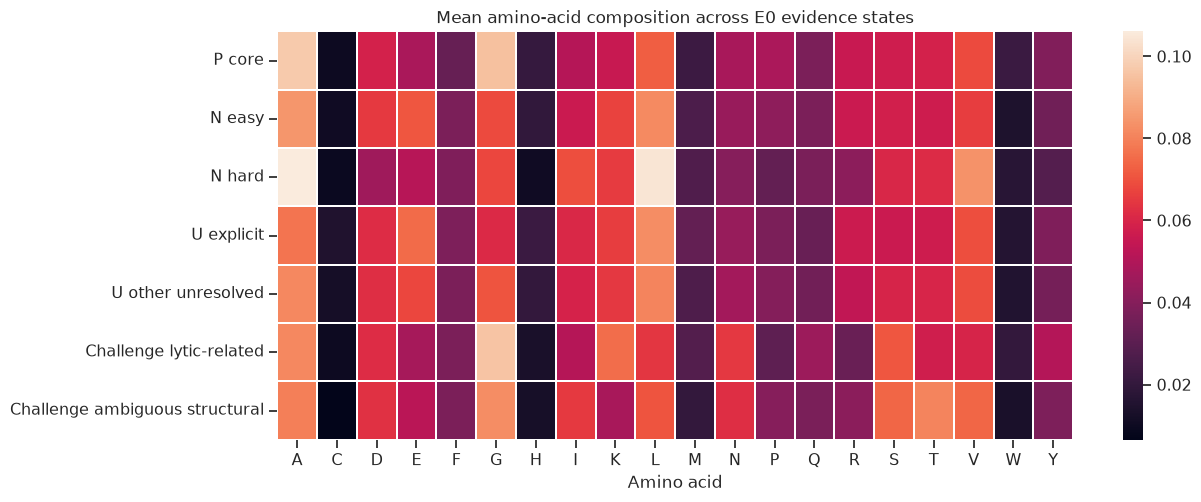

In [16]:
PRIMARY_ORDER = [
    "P_core",
    "N_easy",
    "N_hard",
    "U_explicit",
    "U_other_unresolved",
    "challenge_lytic_related",
    "challenge_ambiguous_structural",
]

PRIMARY_LABELS = {
    "P_core": "P core",
    "N_easy": "N easy",
    "N_hard": "N hard",
    "U_explicit": "U explicit",
    "U_other_unresolved": "U other unresolved",
    "challenge_lytic_related": "Challenge lytic-related",
    "challenge_ambiguous_structural": "Challenge ambiguous structural",
}

aac_primary = (
    primary_summary.loc[
        primary_summary["feature"].isin(AAC_FEATURES)
    ]
    .pivot(
        index="group",
        columns="feature",
        values="mean",
    )
    .reindex(PRIMARY_ORDER)
)

aac_primary = aac_primary[
    AAC_FEATURES
]

aac_primary.columns = [
    short_aac_name(feature)
    for feature in aac_primary.columns
]

aac_primary.index = [
    PRIMARY_LABELS.get(group, group)
    for group in aac_primary.index
]

fig, ax = plt.subplots(
    figsize=(13.0, 5.2)
)

sns.heatmap(
    aac_primary,
    annot=False,
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("Amino acid")
ax.set_ylabel("")
ax.set_title(
    "Mean amino-acid composition across E0 evidence states"
)

fig.tight_layout()
save_figure(
    fig,
    "E2_01_aac_primary_state_profiles",
)
plt.show()

### Figure E2.2 — AAC enrichment/depletion across negative backgrounds

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_02_aac_global_enrichment.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_02_aac_global_enrichment.pdf


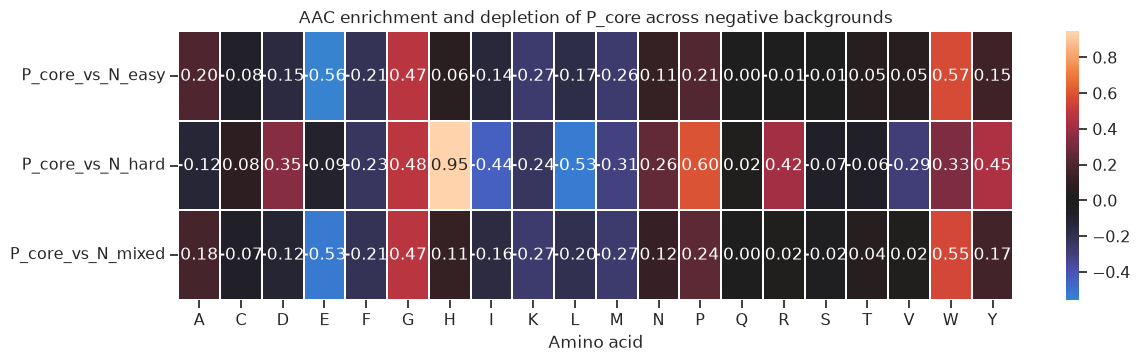

In [17]:
global_enrichment = (
    aac_effects_global.loc[
        aac_effects_global["contrast"].isin(
            [
                "P_core_vs_N_easy",
                "P_core_vs_N_hard",
                "P_core_vs_N_mixed",
            ]
        )
    ]
    .assign(
        amino_acid=lambda x: x["feature"].map(
            short_aac_name
        )
    )
    .pivot(
        index="contrast",
        columns="amino_acid",
        values="log2_mean_ratio",
    )
    .reindex(
        [
            "P_core_vs_N_easy",
            "P_core_vs_N_hard",
            "P_core_vs_N_mixed",
        ]
    )
)

global_enrichment = global_enrichment[
    AA_ORDER
]

fig, ax = plt.subplots(
    figsize=(12.5, 3.8)
)

sns.heatmap(
    global_enrichment,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("Amino acid")
ax.set_ylabel("")
ax.set_title(
    "AAC enrichment and depletion of P_core across negative backgrounds"
)

fig.tight_layout()
save_figure(
    fig,
    "E2_02_aac_global_enrichment",
)
plt.show()

### Figure E2.3 — AAC effect sizes across global contrasts

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_03_aac_global_cliffs_delta.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_03_aac_global_cliffs_delta.pdf


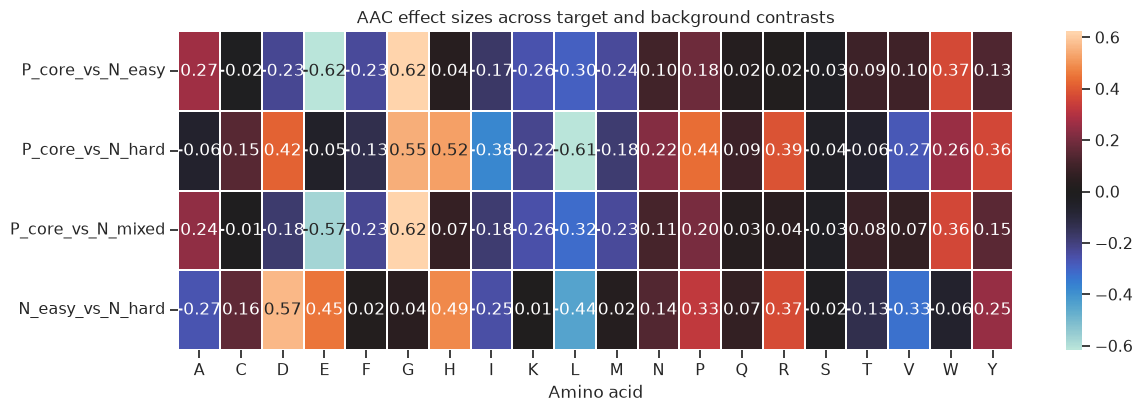

In [18]:
global_delta = (
    aac_effects_global
    .assign(
        amino_acid=lambda x: x["feature"].map(
            short_aac_name
        )
    )
    .pivot(
        index="contrast",
        columns="amino_acid",
        values="cliffs_delta",
    )
    .reindex(
        [
            "P_core_vs_N_easy",
            "P_core_vs_N_hard",
            "P_core_vs_N_mixed",
            "N_easy_vs_N_hard",
        ]
    )
)

global_delta = global_delta[
    AA_ORDER
]

fig, ax = plt.subplots(
    figsize=(12.5, 4.3)
)

sns.heatmap(
    global_delta,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("Amino acid")
ax.set_ylabel("")
ax.set_title(
    "AAC effect sizes across target and background contrasts"
)

fig.tight_layout()
save_figure(
    fig,
    "E2_03_aac_global_cliffs_delta",
)
plt.show()

### Figure E2.4 — AAC effect sizes across clean lytic subtypes

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_04_aac_subtype_cliffs_delta.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_04_aac_subtype_cliffs_delta.pdf


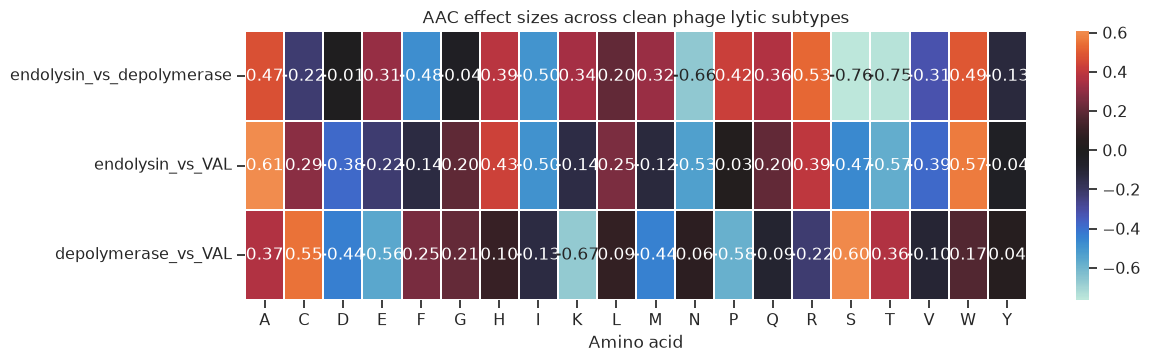

In [19]:
subtype_delta = (
    aac_effects_subtypes
    .assign(
        amino_acid=lambda x: x["feature"].map(
            short_aac_name
        )
    )
    .pivot(
        index="contrast",
        columns="amino_acid",
        values="cliffs_delta",
    )
    .reindex(
        [
            "endolysin_vs_depolymerase",
            "endolysin_vs_VAL",
            "depolymerase_vs_VAL",
        ]
    )
)

subtype_delta = subtype_delta[
    AA_ORDER
]

fig, ax = plt.subplots(
    figsize=(12.5, 3.8)
)

sns.heatmap(
    subtype_delta,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("Amino acid")
ax.set_ylabel("")
ax.set_title(
    "AAC effect sizes across clean phage lytic subtypes"
)

fig.tight_layout()
save_figure(
    fig,
    "E2_04_aac_subtype_cliffs_delta",
)
plt.show()

### Figure E2.5 — Strongest global AAC differences as distributions

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_05_top_global_aac_distributions.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_05_top_global_aac_distributions.pdf


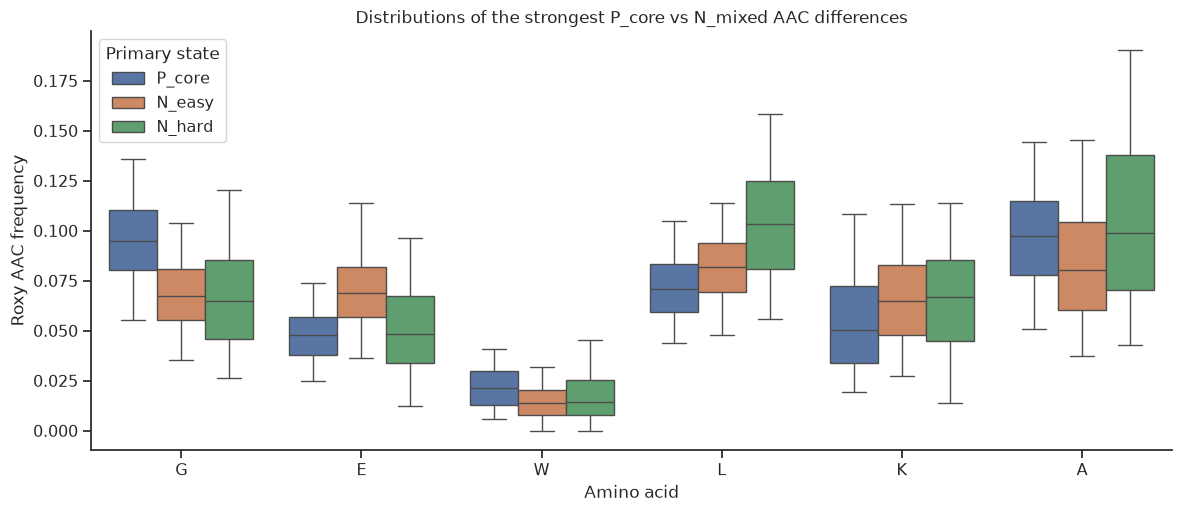

In [20]:
top_global_features = (
    aac_effects_global.loc[
        aac_effects_global["contrast"].eq(
            "P_core_vs_N_mixed"
        )
    ]
    .nlargest(
        6,
        "abs_cliffs_delta",
    )["feature"]
    .tolist()
)

distribution_data = analysis.loc[
    analysis["sequence_state"].isin(
        ["P_core", "N_easy", "N_hard"]
    ),
    ["sequence_state"] + top_global_features,
].melt(
    id_vars="sequence_state",
    value_vars=top_global_features,
    var_name="feature",
    value_name="value",
)

distribution_data["feature"] = (
    distribution_data["feature"].map(
        short_aac_name
    )
)

fig, ax = plt.subplots(
    figsize=(12.0, 5.3)
)

sns.boxplot(
    data=distribution_data,
    x="feature",
    y="value",
    hue="sequence_state",
    hue_order=[
        "P_core",
        "N_easy",
        "N_hard",
    ],
    showfliers=False,
    whis=(5, 95),
    ax=ax,
)

ax.set_xlabel("Amino acid")
ax.set_ylabel("Roxy AAC frequency")
ax.set_title(
    "Distributions of the strongest P_core vs N_mixed AAC differences"
)
ax.legend(title="Primary state")

sns.despine()
fig.tight_layout()
save_figure(
    fig,
    "E2_05_top_global_aac_distributions",
)
plt.show()

### Figure E2.6 — Normalized Shannon entropy across global groups

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_06_entropy_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_06_entropy_global.pdf


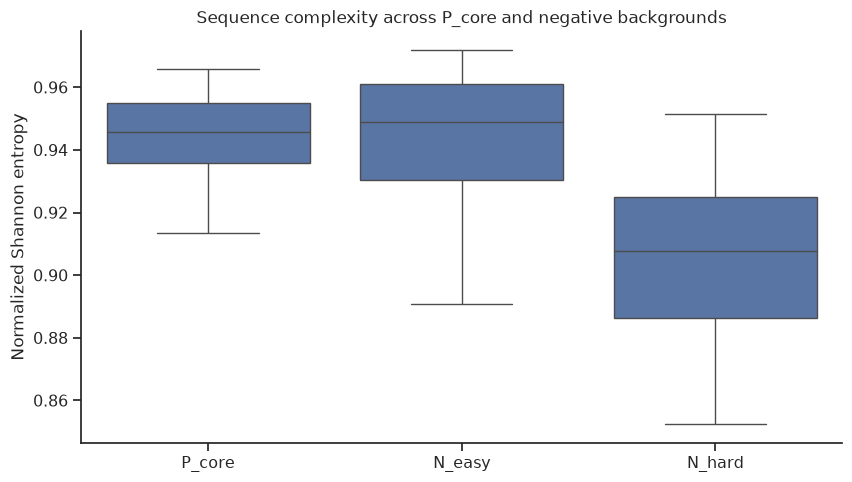

In [21]:
ENTROPY_FEATURE = (
    "entropy_complexity_shannon_entropy_norm"
)

if ENTROPY_FEATURE not in ANALYSIS_FEATURES:
    raise RuntimeError(
        f"Required normalized Shannon entropy feature is missing: "
        f"{ENTROPY_FEATURE}"
    )

plot_global = analysis.loc[
    analysis["sequence_state"].isin(
        ["P_core", "N_easy", "N_hard"]
    ),
    ["sequence_state", ENTROPY_FEATURE],
].copy()

fig, ax = plt.subplots(
    figsize=(8.7, 5.0)
)

sns.boxplot(
    data=plot_global,
    x="sequence_state",
    y=ENTROPY_FEATURE,
    order=[
        "P_core",
        "N_easy",
        "N_hard",
    ],
    showfliers=False,
    whis=(5, 95),
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("Normalized Shannon entropy")
ax.set_title(
    "Sequence complexity across P_core and negative backgrounds"
)

sns.despine()
fig.tight_layout()
save_figure(
    fig,
    "E2_06_entropy_global",
)
plt.show()

### Figure E2.7 — Normalized Shannon entropy across clean lytic subtypes

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_07_entropy_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_07_entropy_clean_subtypes.pdf


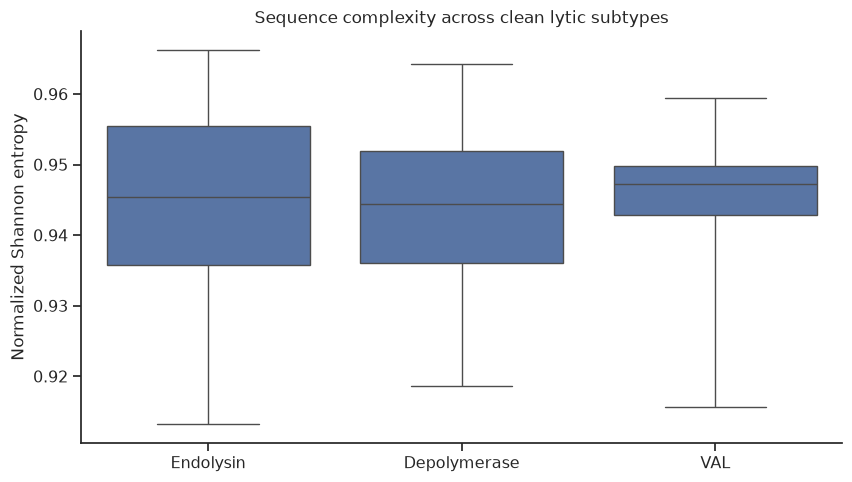

In [22]:
plot_subtypes = P_CLEAN[
    ["clean_subtype", ENTROPY_FEATURE]
].copy()

plot_subtypes["subtype"] = (
    plot_subtypes["clean_subtype"].map(
        SUBTYPE_LABELS
    )
)

fig, ax = plt.subplots(
    figsize=(8.7, 5.0)
)

sns.boxplot(
    data=plot_subtypes,
    x="subtype",
    y=ENTROPY_FEATURE,
    order=[
        "Endolysin",
        "Depolymerase",
        "VAL",
    ],
    showfliers=False,
    whis=(5, 95),
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("Normalized Shannon entropy")
ax.set_title(
    "Sequence complexity across clean lytic subtypes"
)

sns.despine()
fig.tight_layout()
save_figure(
    fig,
    "E2_07_entropy_clean_subtypes",
)
plt.show()

### Figure E2.8 — Strongest normalized composition/complexity effects across global contrasts

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_08_extended_global_cliffs_delta.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_08_extended_global_cliffs_delta.pdf


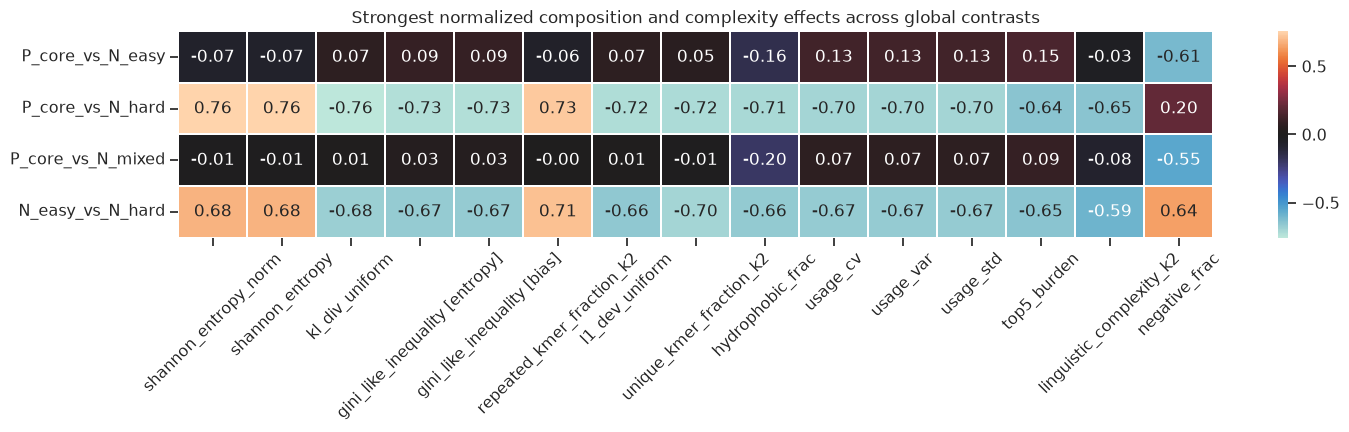

In [23]:
global_feature_rank = (
    composition_effects_global
    .groupby("feature")["abs_cliffs_delta"]
    .max()
    .sort_values(ascending=False)
)

top_extended_global = (
    global_feature_rank
    .head(15)
    .index
    .tolist()
)

# Pivot using the FULL Roxy feature name. Shortened names are only for display.
extended_global_delta = (
    composition_effects_global.loc[
        composition_effects_global["feature"].isin(top_extended_global)
    ]
    .pivot(
        index="contrast",
        columns="feature",
        values="cliffs_delta",
    )
    .reindex(
        [
            "P_core_vs_N_easy",
            "P_core_vs_N_hard",
            "P_core_vs_N_mixed",
            "N_easy_vs_N_hard",
        ]
    )
)

extended_global_delta = extended_global_delta.reindex(
    columns=top_extended_global
)

short_labels = {
    feature: short_feature_name(feature)
    for feature in top_extended_global
}
short_label_counts = pd.Series(
    list(short_labels.values())
).value_counts()

display_labels = {}

for feature in top_extended_global:
    short_label = short_labels[feature]

    if short_label_counts[short_label] > 1:
        if feature.startswith("entropy_complexity_"):
            family = "entropy"
        elif feature.startswith("compositional_bias_"):
            family = "bias"
        elif feature.startswith("grouped_"):
            family = "grouped"
        else:
            family = "feature"

        display_labels[feature] = f"{short_label} [{family}]"
    else:
        display_labels[feature] = short_label

if len(set(display_labels.values())) != len(display_labels):
    raise RuntimeError(
        "Global heatmap display labels remain duplicated after disambiguation."
    )

extended_global_delta = extended_global_delta.rename(
    columns=display_labels
)

fig, ax = plt.subplots(figsize=(15.0, 4.5))

sns.heatmap(
    extended_global_delta,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(
    "Strongest normalized composition and complexity effects across global contrasts"
)
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()

save_figure(
    fig,
    "E2_08_extended_global_cliffs_delta",
)

plt.show()


### Figure E2.9 — Strongest normalized composition/complexity effects across clean subtypes

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_09_extended_subtype_cliffs_delta.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/figures/E2_09_extended_subtype_cliffs_delta.pdf


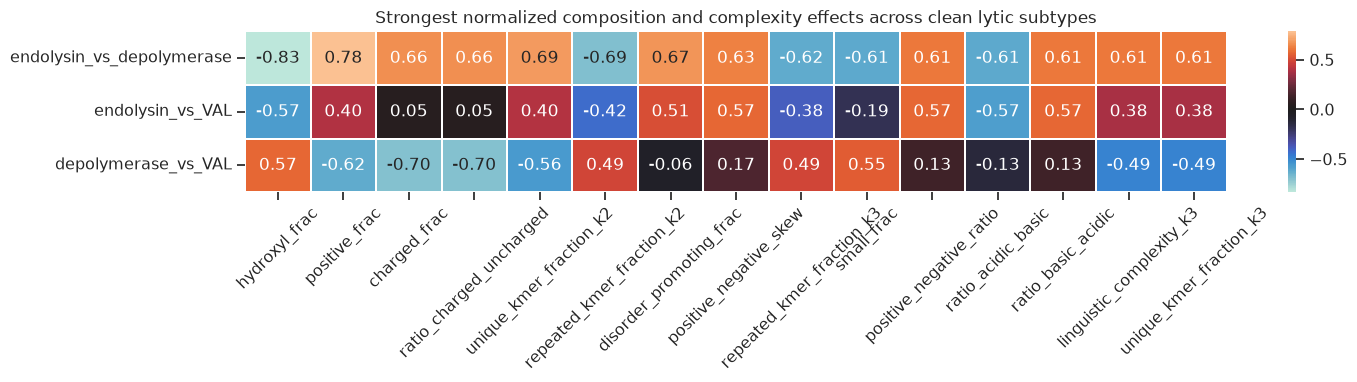

In [24]:
subtype_feature_rank = (
    composition_effects_subtypes
    .groupby("feature")["abs_cliffs_delta"]
    .max()
    .sort_values(ascending=False)
)

top_extended_subtypes = (
    subtype_feature_rank
    .head(15)
    .index
    .tolist()
)

# Pivot using the FULL Roxy feature name. Shortened names are only for display.
extended_subtype_delta = (
    composition_effects_subtypes.loc[
        composition_effects_subtypes["feature"].isin(top_extended_subtypes)
    ]
    .pivot(
        index="contrast",
        columns="feature",
        values="cliffs_delta",
    )
    .reindex(
        [
            "endolysin_vs_depolymerase",
            "endolysin_vs_VAL",
            "depolymerase_vs_VAL",
        ]
    )
)

extended_subtype_delta = extended_subtype_delta.reindex(
    columns=top_extended_subtypes
)

short_labels = {
    feature: short_feature_name(feature)
    for feature in top_extended_subtypes
}
short_label_counts = pd.Series(
    list(short_labels.values())
).value_counts()

display_labels = {}

for feature in top_extended_subtypes:
    short_label = short_labels[feature]

    if short_label_counts[short_label] > 1:
        if feature.startswith("entropy_complexity_"):
            family = "entropy"
        elif feature.startswith("compositional_bias_"):
            family = "bias"
        elif feature.startswith("grouped_"):
            family = "grouped"
        else:
            family = "feature"

        display_labels[feature] = f"{short_label} [{family}]"
    else:
        display_labels[feature] = short_label

if len(set(display_labels.values())) != len(display_labels):
    raise RuntimeError(
        "Subtype heatmap display labels remain duplicated after disambiguation."
    )

extended_subtype_delta = extended_subtype_delta.rename(
    columns=display_labels
)

fig, ax = plt.subplots(figsize=(15.0, 4.0))

sns.heatmap(
    extended_subtype_delta,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(
    "Strongest normalized composition and complexity effects across clean lytic subtypes"
)
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()

save_figure(
    fig,
    "E2_09_extended_subtype_cliffs_delta",
)

plt.show()


## 13. Final closure checks

In [25]:
assert len(roxy_features) == len(e0)
assert roxy_features["sequence_uid"].is_unique

assert len(AAC_FEATURES) == 20
assert AAC_FEATURES == EXPECTED_AAC_FEATURES

assert len(P) == 11_867
assert len(N_EASY) == 54_711
assert len(N_HARD) == 4_327
assert len(N_MIXED) == 59_038

assert int(
    (P_CLEAN["clean_subtype"] == "endolysin").sum()
) == 9_888

assert int(
    (P_CLEAN["clean_subtype"] == "depolymerase").sum()
) == 712

assert int(
    (
        P_CLEAN["clean_subtype"]
        == "virion_associated_lytic_enzyme"
    ).sum()
) == 241

# E2 must not use raw counts or explicit length fields in extended inference.
for feature in EXTENDED_FEATURES:
    if feature.endswith("_length"):
        raise RuntimeError(
            f"Length feature leaked into E2 inference: {feature}"
        )

    if "valid_residue_count" in feature:
        raise RuntimeError(
            f"Valid-residue count leaked into E2 inference: {feature}"
        )

    if feature.startswith("aac_count_"):
        raise RuntimeError(
            f"Raw AAC count leaked into E2 inference: {feature}"
        )

    if (
        feature.startswith("grouped_")
        and feature.endswith("_count")
    ):
        raise RuntimeError(
            f"Grouped raw count leaked into E2 inference: {feature}"
        )

assert (
    "aac_frequency_sum"
    not in ANALYSIS_FEATURES
)

assert (
    "entropy_complexity_longest_homopolymer_run"
    not in EXTENDED_FEATURES
)

assert len(set(top_extended_global)) == len(top_extended_global)
assert len(set(top_extended_subtypes)) == len(top_extended_subtypes)

assert set(aac_effects_global["contrast"]) == {
    "P_core_vs_N_easy",
    "P_core_vs_N_hard",
    "P_core_vs_N_mixed",
    "N_easy_vs_N_hard",
}

assert set(aac_effects_subtypes["contrast"]) == {
    "endolysin_vs_depolymerase",
    "endolysin_vs_VAL",
    "depolymerase_vs_VAL",
}

assert len(aac_effects_global) == 4 * 20
assert len(aac_effects_subtypes) == 3 * 20

assert len(composition_effects_global) == (
    4 * len(EXTENDED_FEATURES)
)

assert len(composition_effects_subtypes) == (
    3 * len(EXTENDED_FEATURES)
)

required_tables = [
    FEATURE_PATH,
    FEATURE_MANIFEST_PATH,
    CACHE_METADATA_PATH,
    ANALYSIS_FEATURE_MANIFEST_PATH,
    MISSINGNESS_PATH,
    GROUP_SUMMARY_PATH,
    AAC_GLOBAL_PATH,
    AAC_SUBTYPE_PATH,
    COMPOSITION_GLOBAL_PATH,
    COMPOSITION_SUBTYPE_PATH,
]

for path in required_tables:
    assert path.is_file(), (
        f"Missing E2 output: {path}"
    )

expected_figure_stems = [
    "E2_01_aac_primary_state_profiles",
    "E2_02_aac_global_enrichment",
    "E2_03_aac_global_cliffs_delta",
    "E2_04_aac_subtype_cliffs_delta",
    "E2_05_top_global_aac_distributions",
    "E2_06_entropy_global",
    "E2_07_entropy_clean_subtypes",
    "E2_08_extended_global_cliffs_delta",
    "E2_09_extended_subtype_cliffs_delta",
]

for stem in expected_figure_stems:
    for suffix in [".png", ".pdf"]:
        figure_path = FIGURE_DIR / f"{stem}{suffix}"

        assert figure_path.is_file(), (
            f"Missing E2 figure: {figure_path}"
        )

print("=" * 72)
print("PASS — E2 sequence composition landscape completed.")
print("=" * 72)
print()
print(f"Roxy feature table        : {FEATURE_PATH}")
print(f"Raw Roxy manifest         : {FEATURE_MANIFEST_PATH}")
print(f"E2 feature manifest       : {ANALYSIS_FEATURE_MANIFEST_PATH}")
print(f"Missingness audit         : {MISSINGNESS_PATH}")
print(f"Group summary             : {GROUP_SUMMARY_PATH}")
print(f"AAC global effects        : {AAC_GLOBAL_PATH}")
print(f"AAC subtype effects       : {AAC_SUBTYPE_PATH}")
print(f"Composition global        : {COMPOSITION_GLOBAL_PATH}")
print(f"Composition subtypes      : {COMPOSITION_SUBTYPE_PATH}")
print(f"Figures                   : {FIGURE_DIR}")

PASS — E2 sequence composition landscape completed.

Roxy feature table        : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/roxy_sequence_composition.parquet
Raw Roxy manifest         : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/roxy_feature_manifest.tsv
E2 feature manifest       : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/analysis_feature_manifest.tsv
Missingness audit         : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/composition_missingness.tsv
Group summary             : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/composition_group_summary.tsv
AAC global effects        : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E2/aac_effects_global.tsv
AAC subtype effects       : /home/david/Desktop/co